Customer Data Shape: (300, 4)


C:\Users\Dineshraj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dineshraj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dineshraj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dineshraj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memor

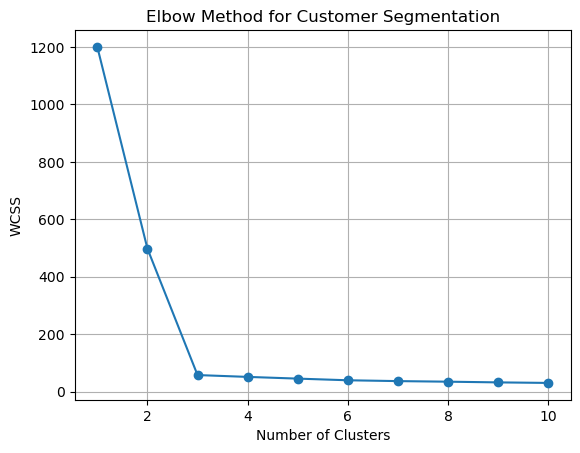

C:\Users\Dineshraj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


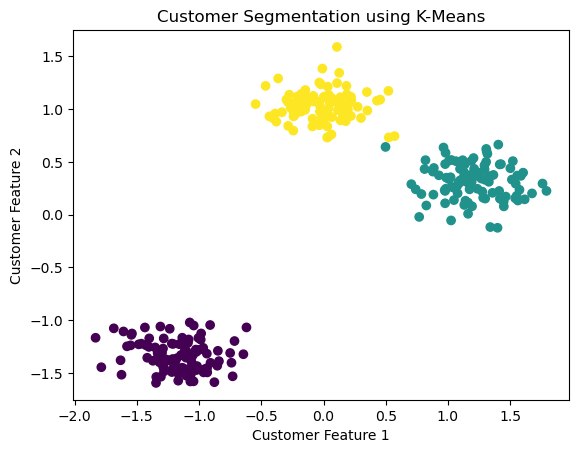

K-Means Silhouette Score: 0.816
Original Shape: (300, 4)
Reduced Shape: (300, 2)
Explained Variance: 0.976


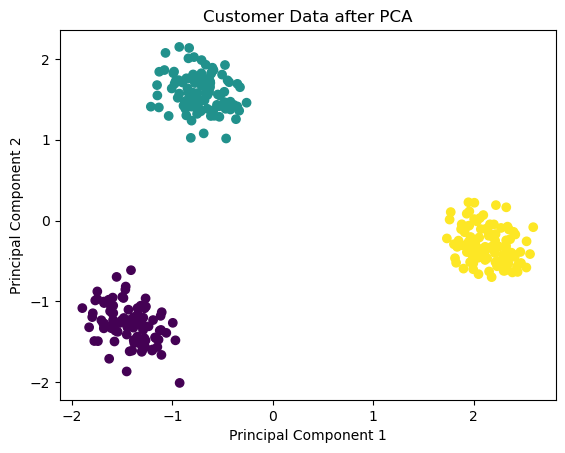

C:\Users\Dineshraj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


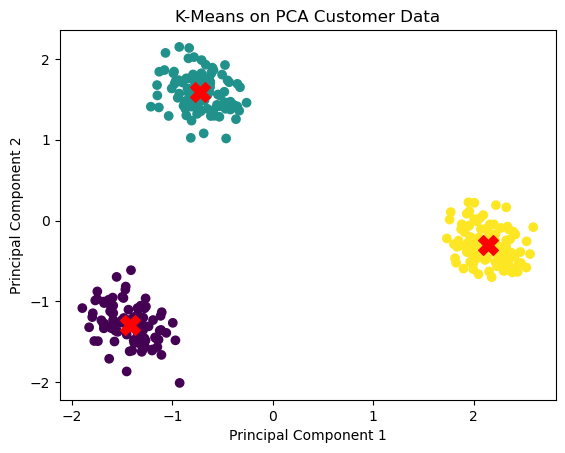

PCA K-Means Silhouette Score: 0.875


In [6]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# PART 1: CUSTOMER SEGMENTATION USING K-MEANS

# 1. Generate customer data
X, _ = make_blobs(n_samples=300, centers=3,
                  n_features=4, random_state=42)

print("Customer Data Shape:", X.shape)

# 2. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid()
plt.show()

# 4. Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

# 5. Visualize customer groups using two features
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters,
            cmap='viridis')
plt.title("Customer Segmentation using K-Means")
plt.xlabel("Customer Feature 1")
plt.ylabel("Customer Feature 2")
plt.show()

# 6. Evaluate clustering
print("K-Means Silhouette Score:",
      round(silhouette_score(X_scaled, clusters), 3))


# PART 2: PCA FOR CUSTOMER DATA

# 1. Reduce 4 features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("Reduced Shape:", X_pca.shape)
print("Explained Variance:",
      round(sum(pca.explained_variance_ratio_), 3))

# 2. Visualize PCA result
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters,
            cmap='viridis')
plt.title("Customer Data after PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# 3. Apply K-Means on PCA-reduced data
kmeans_pca = KMeans(n_clusters=3, n_init=10, random_state=42)
pca_clusters = kmeans_pca.fit_predict(X_pca)

# 4. Visualize PCA clusters and centroids
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=pca_clusters, cmap='viridis')
plt.scatter(kmeans_pca.cluster_centers_[:, 0],
            kmeans_pca.cluster_centers_[:, 1],
            color='red', marker='X', s=200)
plt.title("K-Means on PCA Customer Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# 5. Evaluate PCA clustering
print("PCA K-Means Silhouette Score:",
      round(silhouette_score(X_pca, pca_clusters), 3))
